# GitHub Link: 
https://github.com/RhuanMendanha/CA01-Data-Visualisation-and-Communication-.git 

# Introduction:

The purpose of this notebook is to harness visualization to examine employment trends related to artificial intelligence (AI), data science, and software programming within the U.S. 

Data. The primary data source is the Occupational Employment and Wage Statistics (OEWS) “All data” file for May 2023 released by U.S. Bureau of Labor Statistics (2024), also known as BLS. This file contains 413,327 employment and wage estimates by occupation, geography (nation, state, and metropolitan area) and industry. The challenge section, besides making use of the national OEWS files of May 2014-May 2022 (BLS, 2015-2023) from the same page, focuses on trend analysis. 

Defining "AI employment." BLS uses the Standard Occupational Classification (SOC) which lacks a separate category for AI or machine learning engineers (Office of Management and Budget, 2018). As a result, AI jobs are studied through using proxy occupations.

| Family | SOC 2018 occupations used |
|---|---|
| **AI & Computing Research** | 15-1221 Computer & Information Research Scientists (the SOC group that includes AI/ML researchers) |
| **Data Science & Analytics** | 15-2051 Data Scientists, 15-2041 Statisticians, 15-2031 Operations Research Analysts, 15-2021 Mathematicians, 15-1243 Database Architects |
| **Software Development** | 15-1252 Software Developers, 15-1253 Software QA Analysts & Testers, 15-1251 Computer Programmers, 15-1254 Web Developers |

All families use the same color for all charts (blue, orange, aqua - a color-blind safe color set) to allow the reader to follow it in the notebook.

Running instructions: You need to download oesm23all.zip and oesm14nat.zip and oesm22nat.zip from https://www.bls.gov/oes/tables.htm and save these zip files (don’t extract them) to a folder called data/ which needs to be next to this notebook.

## 2. Setup
Libraries: **pandas** for data handling (McKinney, 2010), **matplotlib** (Hunter, 2007) and **seaborn** (Waskom, 2021) for the visualisations.

In [1]:
# ---------- 1. Bringing in our toolboxes ----------
# Python on its own can't do everything, so we "import" toolboxes (libraries)
# that other people built. Think of it like taking tools out of a shed.

import zipfile, re            # zipfile = opens .zip files (like unzipping a folder)
                              # re = finds patterns in text (like a smart "search")
from pathlib import Path      # Path = helps us write folder/file locations properly
import numpy as np            # numpy = super-fast maths with lots of numbers at once
import pandas as pd           # pandas = works with tables, like Excel inside Python
import matplotlib.pyplot as plt          # matplotlib = the main tool for drawing charts
import matplotlib.ticker as mtick        # ticker = changes how axis numbers look (e.g. 1,000 or $50,000)
from matplotlib.colors import TwoSlopeNorm  # makes a colour scale with a "middle point"
                                            # (we use it in the heatmap, where 1.0 = average)
import seaborn as sns         # seaborn = draws nicer charts more easily (built on matplotlib)

# ---------- 2. How tables are shown on screen ----------
# By default pandas hides columns when a table is wide.
# These two lines say: "show up to 40 columns and make the table wider".
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# ---------- 3. One style for all charts ----------
# Instead of styling every chart one by one, we set the rules ONCE here.
# It's like choosing the font and colours for a whole school project at the start.
plt.rcParams.update({
    "figure.dpi": 110,              # how sharp the picture is (more dots = clearer)
    "axes.spines.top": False,       # remove the line at the top of the chart (looks cleaner)
    "axes.spines.right": False,     # remove the line on the right side too
    "axes.grid": True,              # draw light helper lines behind the chart
    "grid.color": "#e6e6e3",        # those helper lines are very light grey
    "grid.linewidth": 0.8,          # and thin, so they don't distract
    "axes.axisbelow": True,         # put the helper lines BEHIND the bars, not on top
    "axes.titleweight": "bold",     # chart titles in bold
    "axes.titlesize": 13,           # title text size
    "axes.labelcolor": "#52514e",   # axis labels in dark grey (softer than black)
    "xtick.color": "#52514e",       # numbers on the bottom axis in dark grey
    "ytick.color": "#52514e",       # numbers on the side axis in dark grey
    "font.size": 10,                # normal text size
})
# The "#e6e6e3"-style codes are colours written in "hex" code: a way
# computers name colours using numbers and letters.

# ---------- 4. A colour for each job family ----------
# A dictionary is like a mini phone book: you look up a name and get a value.
# Here: look up a job family and get its colour.
# We always use the SAME colour for the same family, in every chart,
# so the reader learns "blue = AI research" and never gets confused.
# These colours are also easy to tell apart for colour-blind people.
FAMILY_COLOURS = {
    "AI & Computing Research": "#2a78d6",   # blue
    "Data Science & Analytics": "#eb6834",  # orange
    "Software Development": "#1baf7a",      # aqua (blue-green)
}
GREY = "#b9b8b3"   # grey for "everything else", so the important things stand out

# ---------- 5. Where the data lives ----------
# This tells Python: "the data files are inside a folder called 'data'".
# The zip files go in there, but we don't upload them with the homework.
DATA_DIR = Path("data")

# A little message to prove everything loaded without errors,
# and to show which version of pandas we're using.
print("Libraries loaded. pandas", pd.__version__)

Libraries loaded. pandas 3.0.3


## 3. Loading the May 2023 data
The Excel file is read directly from inside the zip, so no manual unzipping is needed (loading takes 1–2 minutes because the file is large).

In [2]:
# ---------- Reading the Excel file straight out of the zip ----------
# The BLS gives us a .zip file (like a squashed folder) with an Excel file inside.
# Instead of unzipping it by hand, we write our own little "machine" (a function)
# that opens the zip, finds the right file and reads it for us.

def read_excel_from_zip(zip_path, pattern):
    # "def" means: "I'm creating a function". A function is a set of steps with a name,
    # so we can use it again later just by calling its name.
    # It needs two things (inputs):
    #   zip_path = where the zip file is
    #   pattern  = a description of the file name we're looking for inside the zip

    """Read the first .xlsx inside a BLS zip whose name matches `pattern` (no manual unzipping needed)."""
    # ^ This is a "docstring": a short note explaining what the function does.

    with zipfile.ZipFile(zip_path) as z:
        # Open the zip file and call it "z".
        # "with" means: when we're finished, close it automatically (like closing a door behind you).

        member = next(n for n in z.namelist() if re.search(pattern, n, re.I))
        # z.namelist() = a list of every file name inside the zip.
        # We go through them one by one ("for n in ...") and check if the name
        # matches our pattern ("re.search"). re.I means "ignore capital/small letters".
        # next(...) = "give me the FIRST one that matches".
        # The file we found is saved as "member".

        with z.open(member) as f:
            # Open that file inside the zip (still without unzipping anything) and call it "f".

            return pd.read_excel(f)
            # pandas reads the Excel file and turns it into a table (a "DataFrame").
            # "return" = hand that table back to whoever called the function.


# ---------- Using our function ----------
raw = read_excel_from_zip(DATA_DIR / "oesm23all.zip", r"all_data_M_2023\.xlsx$")
# Use the machine: "open data/oesm23all.zip and find the file named all_data_M_2023.xlsx".
#   DATA_DIR / "oesm23all.zip"  -> joins the folder and the file name into one path.
#   r"all_data_M_2023\.xlsx$"   -> the pattern:
#        r"..." = a "raw" string, so Python doesn't treat backslashes as special
#        \.     = a real dot (in patterns, a plain "." means "any character")
#        $      = the name must END here
# The whole table is saved in a variable called "raw" (raw = not cleaned yet).
# This line is slow (1–2 minutes) because the file has over 400,000 rows.

print(raw.shape)
# .shape tells us the size of the table: (number of rows, number of columns).
# Here it prints (413327, 32) -> 413,327 rows and 32 columns.

raw.head(3)
# Show the first 3 rows, so we can have a quick look at what the data looks like.
# Because it's the last line of the cell, Jupyter shows it as a nice table.

(413327, 32)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,EMP_PRSE,JOBS_1000,LOC_QUOTIENT,PCT_TOTAL,PCT_RPT,H_MEAN,A_MEAN,MEAN_PRSE,H_PCT10,H_PCT25,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,total,151853870,0,NaN,NaN,NaN,NaN,31.48,65470,0.3,13.97,17.14,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,major,10495770,0.4,NaN,NaN,NaN,NaN,66.23,137750,0.5,26.23,37.66,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,minor,3751510,0.4,NaN,NaN,NaN,NaN,65.43,136100,0.9,22.31,31.81,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN


## 4. Cleaning and selecting the data

The Bureau of Labor Statistics applies the following notations in its tables: * and ** denote that information is not provided, and # indicates that the salary is above $239,200. The notation of # is interpreted as 239,200, while */** indicates a void.

The analysis prefers the rows of the data indicating the domestic level, any industry, any ownership (AREA_TYPE = 1, I_GROUP = "cross-industry", OWN_CODE = 1235), and thus prevents double-counting of jobs within the same sector.

In [3]:
# BLS uses symbols instead of numbers:
#   '*'  = wage not available,  '**' = employment not available
#   '#'  = wage is very high (at least $239,200/year), BLS stops counting there
NUM_COLS = ["TOT_EMP", "EMP_PRSE", "JOBS_1000", "LOC_QUOTIENT", "PCT_TOTAL", "PCT_RPT",
            "H_MEAN", "A_MEAN", "MEAN_PRSE", "A_PCT10", "A_PCT25", "A_MEDIAN", "A_PCT75", "A_PCT90"]

df = raw.copy()  # work on a copy so the original table stays safe
for col in NUM_COLS:  # fix every number column, one at a time
    s = df[col].astype(str).str.strip()  # turn values into text and remove extra spaces
    if col.startswith("A_"):  # yearly wage columns
        s = s.replace("#", "239200")  # use the cap: the real wage is at least this much
    # symbols become NaN (missing, NOT zero), then text becomes real numbers
    df[col] = pd.to_numeric(s.replace({"*": np.nan, "**": np.nan, "~": np.nan}), errors="coerce")

# No official "AI job" code exists, so we pick the closest jobs.
# Each code points to (short name, family)
OCCUPATIONS = {
    "15-1221": ("Computer & Information Research Scientists", "AI & Computing Research"),
    "15-2051": ("Data Scientists",                            "Data Science & Analytics"),
    "15-2041": ("Statisticians",                              "Data Science & Analytics"),
    "15-2031": ("Operations Research Analysts",               "Data Science & Analytics"),
    "15-2021": ("Mathematicians",                             "Data Science & Analytics"),
    "15-1243": ("Database Architects",                        "Data Science & Analytics"),
    "15-1252": ("Software Developers",                        "Software Development"),
    "15-1253": ("Software QA Analysts & Testers",             "Software Development"),
    "15-1251": ("Computer Programmers",                       "Software Development"),
    "15-1254": ("Web Developers",                             "Software Development"),
}
# turn the dictionary into a small table: job code -> name and family
occ_map = pd.DataFrame.from_dict(OCCUPATIONS, orient="index", columns=["OCC", "FAMILY"])
occ_map.index.name = "OCC_CODE"

# Keep each job only once: whole USA, all industries, all employers
national = df[(df.AREA_TYPE == 1) & (df.I_GROUP == "cross-industry") & (df.OWN_CODE == 1235)]

# keep only our AI jobs and attach their name and family (matched by job code)
ai = (national[national.OCC_CODE.isin(OCCUPATIONS)]
      .merge(occ_map, left_on="OCC_CODE", right_index=True))

# show the 10 jobs, biggest first
ai[["OCC_CODE", "OCC", "FAMILY", "TOT_EMP", "A_MEAN", "A_MEDIAN"]].sort_values("TOT_EMP", ascending=False)

,OCC_CODE,OCC,FAMILY,TOT_EMP,A_MEAN,A_MEDIAN
149,15-1252,Software Developers,Software Development,1656880.0,138110.0,132270.0
150,15-1253,Software QA Analysts & Testers,Software Development,203040.0,108460.0,101800.0
165,15-2051,Data Scientists,Data Science & Analytics,192710.0,119040.0,108020.0
148,15-1251,Computer Programmers,Software Development,120370.0,107750.0,99700.0
161,15-2031,Operations Research Analysts,Data Science & Analytics,117880.0,95600.0,83640.0
151,15-1254,Web Developers,Software Development,85350.0,95570.0,84960.0
145,15-1243,Database Architects,Data Science & Analytics,59920.0,137030.0,134700.0
138,15-1221,Computer & Information Research Scientists,AI & Computing Research,35210.0,157160.0,145080.0
163,15-2041,Statisticians,Data Science & Analytics,29950.0,109190.0,104110.0
159,15-2021,Mathematicians,Data Science & Analytics,2220.0,119770.0,116440.0


## Visualisation 1 – Horizontal bar chart: how many people work in each occupation?

Objective: comparison - to assess the size of various AI, data, and software jobs.

Why a horizontal bar chart: this specific diagram is used since there is one categorical variable (the occupation) and one quantitative variable (the employment). The bar length is the best visual representation for comparison of sizes, and the horizontal bars are optimal for long names of the occupations. The Software Developer occupation has approximately 1.66 million job listings, therefore it is roughly 750 times bigger than the job of a Mathematician (2,220).

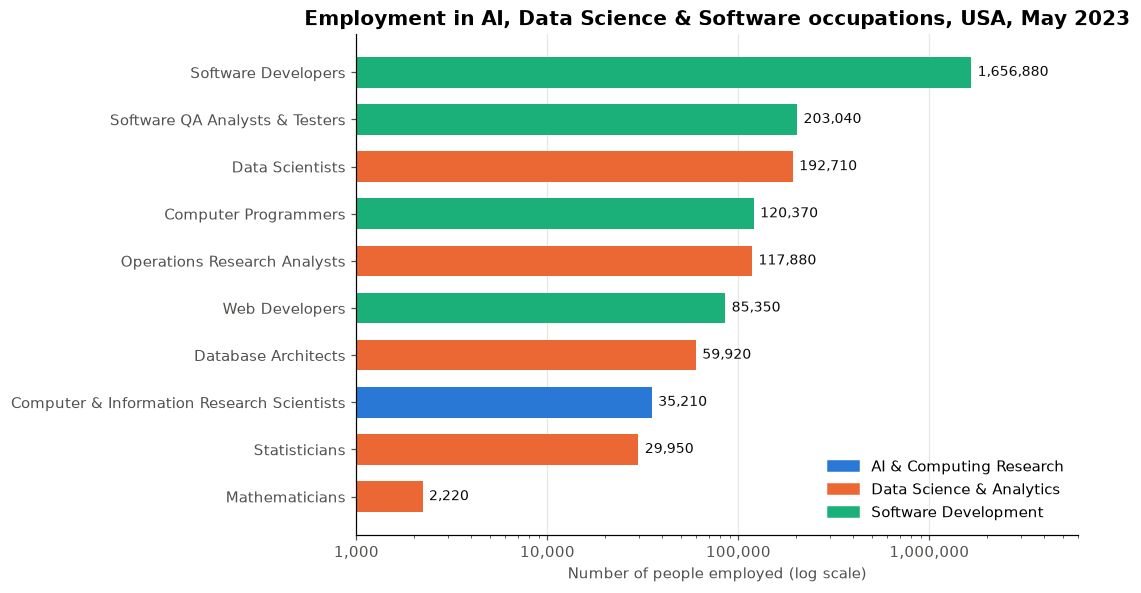

In [4]:
# sort smallest to biggest (barh draws from the bottom, so the biggest ends up on top)
d = ai.sort_values("TOT_EMP")

# create an empty chart: fig = the whole picture, ax = the drawing area
fig, ax = plt.subplots(figsize=(10, 5.5))

# draw horizontal bars: one per job, length = number of workers, colour = its family
bars = ax.barh(d.OCC, d.TOT_EMP, color=d.FAMILY.map(FAMILY_COLOURS), height=0.65)

# log scale: each step is x10, so small jobs are still visible next to huge ones
ax.set_xscale("log")
# show axis numbers as 1,000 / 10,000 instead of scientific notation
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))

# write the exact number just after the end of each bar
for b, v in zip(bars, d.TOT_EMP):
    ax.text(v * 1.08, b.get_y() + b.get_height() / 2, f"{v:,.0f}", va="center", fontsize=9, color="#0b0b0b")

ax.set_xlim(1_000, 6_000_000)       # axis range, with space on the right for the labels
ax.grid(axis="y", visible=False)    # remove horizontal grid lines (bars are enough)
ax.set_xlabel("Number of people employed (log scale)")
ax.set_title("Employment in AI, Data Science & Software occupations, USA, May 2023")

# legend: make one coloured square per family and label it with the family name
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLOURS.values()]
ax.legend(handles, FAMILY_COLOURS.keys(), loc="lower right", frameon=False)

plt.tight_layout(); plt.show()      # fix spacing so nothing is cut off, then show the chart

### Here are my personal observations regarding the employment of AI:

The major employment contributors are software developers with the number of work positions being 1,656,880. This number takes up around two third of the number of working positions across 10 occupations (2.5 million jobs).
Data scientists work in the largest number as compared with other types of occupations in the sector (that is, 192,710). The number of data scientists exceeds the number of computer programmers (120,370) and operations research analysts (117,880). It is also more than six times bigger than the number of statisticians.
Computer and information research scientists hold the closest position to AI research. However, the number of their jobs in this field is significantly low (35,210). AI is evidently more of a research niche. Most activities in the field are performed by software developers and other people working in Data Science.

## Visualisation 2 – Donut chart: how is the workforce composed?

Aim: donut chart – what proportion of the total workforce in AI/data/software belongs to each family, and what is the total workforce in terms of the whole US workforce.

Reason for choosing donut chart: there are only three categories, which makes the use of a pie chart especially suitable. A donut chart has a hole in the middle that allows to put the total amount of jobs (2.50M) and the percentage of the total amount of jobs in the USA directly into the centre.

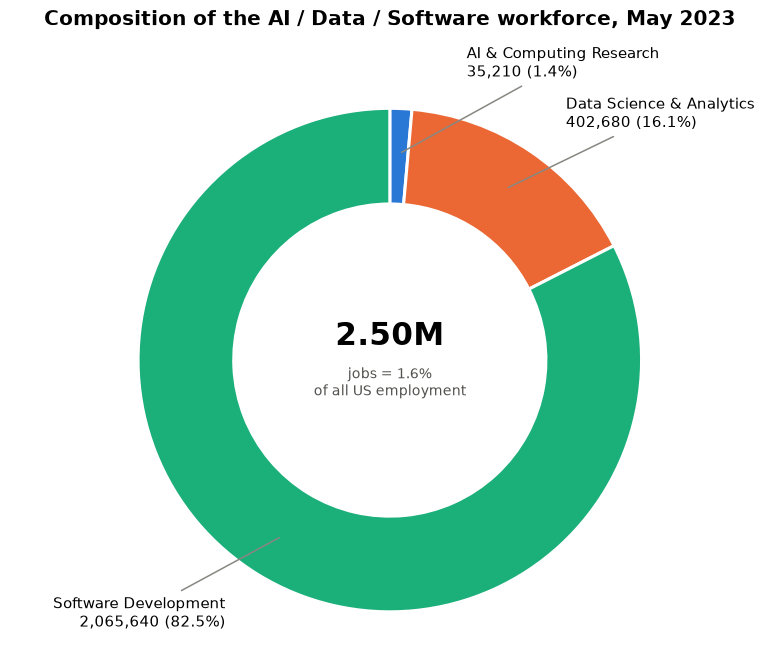

Total US employment: 151,853,870


In [5]:
# add up the workers in each family, kept in the same order as our colours
fam = ai.groupby("FAMILY").TOT_EMP.sum().reindex(FAMILY_COLOURS.keys())
# total jobs in the whole USA (code 00-0000 = "All Occupations")
total_us = national.loc[national.OCC_CODE == "00-0000", "TOT_EMP"].iloc[0]

fig, ax = plt.subplots(figsize=(7.5, 6))

# draw the pie: start at the top (90°), go clockwise;
# width=0.38 cuts a hole in the middle, which turns it into a donut
wedges, _ = ax.pie(fam, colors=fam.index.map(FAMILY_COLOURS), startangle=90, counterclock=False,
                   wedgeprops=dict(width=0.38, edgecolor="white", linewidth=2))

# add a label with an arrow line to each slice
for w, (name, val) in zip(wedges, fam.items()):
    ang = np.deg2rad((w.theta2 + w.theta1) / 2)   # the angle in the middle of the slice
    x, y = np.cos(ang), np.sin(ang)               # turn that angle into a position (x, y)
    # label text: family name, number of jobs and its % of the donut
    # xy = where the line starts (on the slice), xytext = where the text goes (outside)
    # tiny slices (under 5%) get their label pushed further out so it doesn't overlap
    ax.annotate(f"{name}\n{val:,.0f} ({val / fam.sum():.1%})", xy=(0.82 * x, 0.82 * y), xytext=(1.25 * x + (0.25 if val / fam.sum() < 0.05 else 0), 1.18 * y),
                ha="left" if x > 0 else "right", va="center", fontsize=10,
                arrowprops=dict(arrowstyle="-", color="#898781"))

# text in the hole: the total (in millions), and its share of ALL US jobs
ax.text(0, 0.06, f"{fam.sum() / 1e6:.2f}M", ha="center", fontsize=20, fontweight="bold")
ax.text(0, -0.14, f"jobs = {fam.sum() / total_us:.1%}\nof all US employment", ha="center", fontsize=9, color="#52514e")

ax.set_title("Composition of the AI / Data / Software workforce, May 2023", pad=38)  # pad = space above the chart
ax.axis("equal"); plt.tight_layout(); plt.show()   # "equal" keeps the donut round, not oval
print(f"Total US employment: {total_us:,.0f}")

### What I have learn about AI Employment:

The data reveals that the field of Software Development makes up the largest part of employment in Artificial Intelligence consisting of 82.5% or more than 2 million people. The other sectors are Data Science and Analytics (16.1% or more than 400,000 jobs) and AI and Computing research (just 1.4%, or 35,000 jobs). The whole group of ten professions represents just 1.6% of the total number of jobs in the country which is 151.9 million. While AI as a field appears to be quite popular in the news, it represents just a tiny fraction of job opportunities in the country as of May 2023.

## Visualisation 3 – Box plot: what is the amount of salary for various jobs and the variability in salary?

Aim: distribution – assessing not only the average (median) salary but also the span of salaries for every occupation.

Reason for using a box plot: the wage is a variable of continuous nature and average alone makes the wage distributions look too equal. The OEWS data set gives the 10, 25, 50, 75, 90 percentiles, which correspond to the box plot. The box plot is useful for comparing numerous distributions at once.

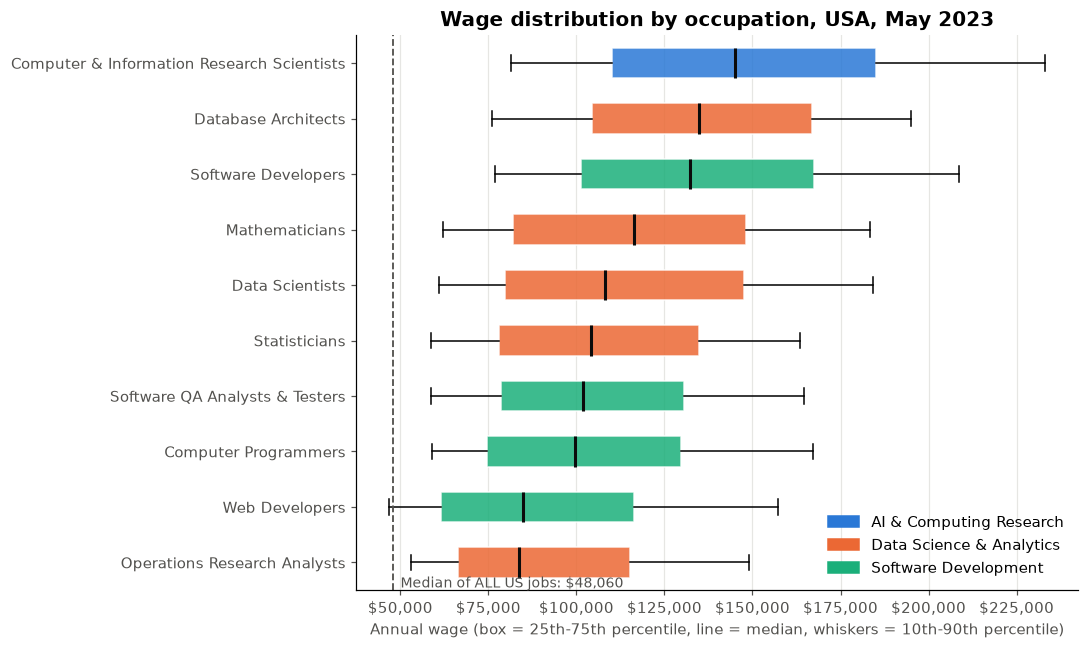

In [6]:
# median wage of ALL US jobs, used as a reference line
all_median = national.loc[national.OCC_CODE == "00-0000", "A_MEDIAN"].iloc[0]
d = ai.sort_values("A_MEDIAN")   # lowest median at the bottom, highest at the top

# we don't have every single salary, only the BLS percentiles,
# so we build each box ourselves from those 5 numbers:
#   whislo/whishi = whisker ends (10th and 90th percentile)
#   q1/q3 = box edges (25th and 75th), med = middle line (median)
#   fliers=[] = no outlier dots
stats = [dict(label=r.OCC, whislo=r.A_PCT10, q1=r.A_PCT25, med=r.A_MEDIAN, q3=r.A_PCT75, whishi=r.A_PCT90, fliers=[])
         for r in d.itertuples()]

fig, ax = plt.subplots(figsize=(10, 6))
# bxp draws box plots from ready-made numbers; patch_artist=True lets us colour the boxes
bp = ax.bxp(stats, orientation="horizontal", patch_artist=True, showfliers=False, widths=0.55,
            medianprops=dict(color="#0b0b0b", linewidth=2))

# colour each box with its family colour
for patch, f in zip(bp["boxes"], d.FAMILY):
    patch.set_facecolor(FAMILY_COLOURS[f]); patch.set_alpha(0.85); patch.set_edgecolor("white")

# dashed line + label for the median of all US jobs
ax.axvline(all_median, color="#52514e", ls="--", lw=1.2)
ax.text(all_median + 2_000, 0.55, f"Median of ALL US jobs: ${all_median:,.0f}", fontsize=9, color="#52514e")

ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))   # axis shows $50,000 style
ax.set_xlabel("Annual wage (box = 25th-75th percentile, line = median, whiskers = 10th-90th percentile)")
ax.set_title("Wage distribution by occupation, USA, May 2023")
ax.grid(axis="y", visible=False)

# same legend as before: one coloured square per family
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLOURS.values()]
ax.legend(handles, FAMILY_COLOURS.keys(), loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

### Here is what I learnt about the employment sector in relation to AI:

All the jobs listed here pay well above the national median salary of USD 48,060. Even the lowest-paid job, Operations Research Analyst, earns 1.7 times the national median.

Computer and Information Research Scientist has the highest median salary, USD 145,080, as well as the highest salary potential, with the top 10% earning USD 233,110 or more.

Software Developer (USD 132,270) and Database Architect (USD 134,700) come next. Data Scientists have a median salary of USD 108,020, but salaries vary considerably, with professionals at the 90th percentile earning USD 184,090.

## Visualisation 4 - Scatter Plot: What Is The Comparison Among These Professions To Others?

Objective: Relationship / Investigation - Does the number of people working in one profession connect in any way with its salary level? Where do the professions related to artificial intelligence stand among 826 other professions?

Reason behind using a scatter plot: the two variables used here (the number of people employed in the given profession and median wage) are numeric ones, and scatter plot is a typical method of representing the connection between two numeric variables. In this case, the employment variable has the logarithmic scale, as its values range from several hundred to several millions. Other professions are painted light grey so that the ten jobs selected are distinguishable.

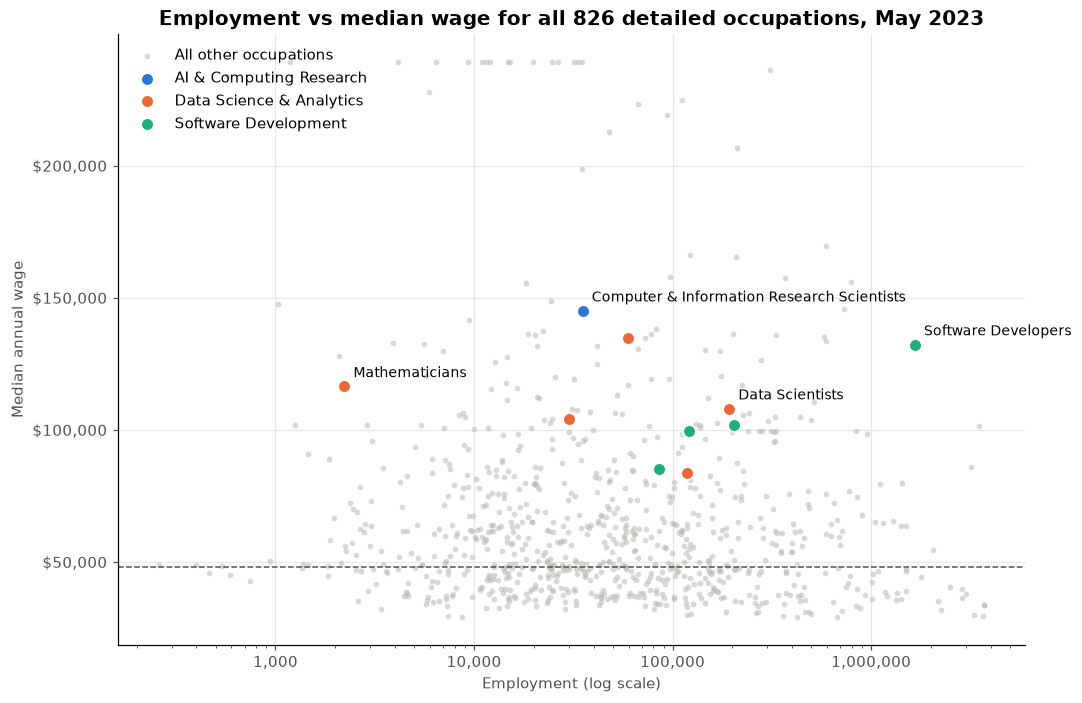

,wage percentile,OCC_TITLE
138,0.959,Computer and Information Research Scientists
145,0.946,Database Architects
149,0.941,Software Developers
159,0.915,Mathematicians
165,0.904,Data Scientists
163,0.887,Statisticians
150,0.878,Software Quality Assurance Analysts and Testers
148,0.860,Computer Programmers
151,0.795,Web Developers
161,0.780,Operations Research Analysts


In [7]:
# every individual job in the USA that has both a job count and a median wage
detailed = national[(national.O_GROUP == "detailed")].dropna(subset=["TOT_EMP", "A_MEDIAN"]).copy()
# give our AI jobs their family name; all other jobs get NaN (empty)
detailed["FAMILY"] = detailed.OCC_CODE.map(occ_map.FAMILY)
others = detailed[detailed.FAMILY.isna()]   # all the non-AI jobs
tech = detailed[detailed.FAMILY.notna()].merge(occ_map[["OCC"]], left_on="OCC_CODE", right_index=True)  # our 10 jobs + short names

fig, ax = plt.subplots(figsize=(10, 6.5))
# first, all other jobs as small, faded grey dots (the background)
ax.scatter(others.TOT_EMP, others.A_MEDIAN, s=14, color=GREY, alpha=0.55, label="All other occupations", linewidths=0)

# then our jobs as big coloured dots, one colour per family;
# zorder=3 draws them ON TOP of the grey dots
for fam_name, g in tech.groupby("FAMILY"):
    ax.scatter(g.TOT_EMP, g.A_MEDIAN, s=70, color=FAMILY_COLOURS[fam_name], edgecolor="white", linewidth=1.2,
               label=fam_name, zorder=3)

# write the name next to a few important dots only (all 10 would be too crowded)
for r in tech.itertuples():
    if r.OCC in ("Software Developers", "Data Scientists", "Computer & Information Research Scientists", "Mathematicians"):
        ax.annotate(r.OCC, (r.TOT_EMP, r.A_MEDIAN), xytext=(6, 6), textcoords="offset points", fontsize=9)

ax.axhline(all_median, color="#52514e", ls="--", lw=1)   # dashed line = median of all US jobs
ax.set_xscale("log")   # job counts go from hundreds to millions, so use a log scale
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_xlabel("Employment (log scale)"); ax.set_ylabel("Median annual wage")
ax.set_title(f"Employment vs median wage for all {len(detailed)} detailed occupations, May 2023")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

# rank every job by median wage as a percentile (0 = lowest paid, 1 = highest paid),
# keep only our 10 jobs and add their full titles
pct_rank = (detailed.A_MEDIAN.rank(pct=True)[detailed.FAMILY.notna()]
            .rename("wage percentile").to_frame().join(detailed.set_index(detailed.index)[["OCC_TITLE"]]))
# show them from best paid to least paid, e.g. 0.959 = paid more than about 96% of all jobs
pct_rank.sort_values("wage percentile", ascending=False).round(3)

### Here are my personal observations regarding the employment of AI:

On the whole, large occupations tend to have lower pay than smaller occupations as evident from the grey points in the bottom right side of the chart (like retail and food service). 
With the software development profession, we see a major exception; this profession is among the largest and most lucrative. 
In total, in the USA, out of ten occupations related to AI/data/software, each belongs to the top 25% of the highest-paying occupations (see the table above). An interesting fact is that the row of grey points in the upper part of the diagram is the ceiling of wages delineated by the Bureau of Labour Statistics ($239,200) for the majority of professions, which are connections primarily with medicine.

## Visualization 5 – Heat map: in which states of the USA do the most jobs belong to the occupations of interest?

Aim: analysis – what is the geographical distribution of jobs in artificial intelligence, data and software?

Why the heat map: the data consists of values for the two categorical variables (state × occupation) and one continuous (location quotient). Location quotient is calculated as follows: location quotient = state share of jobs in the profession / national share of jobs in the profession; thus, if location quotient equals to 1.0, it is average, if location quotient equals to 2.0, it means twice higher than average. Taking into consideration that the location quotient has a natural midpoint which is equal to 1, the diverging colour scale is applied: red colour means above average level of concentration of jobs, blue colour means that the level of concentration of jobs is lower than average, white colour means average level. The values are placed in each cell and do not rely only on colour differentiation.

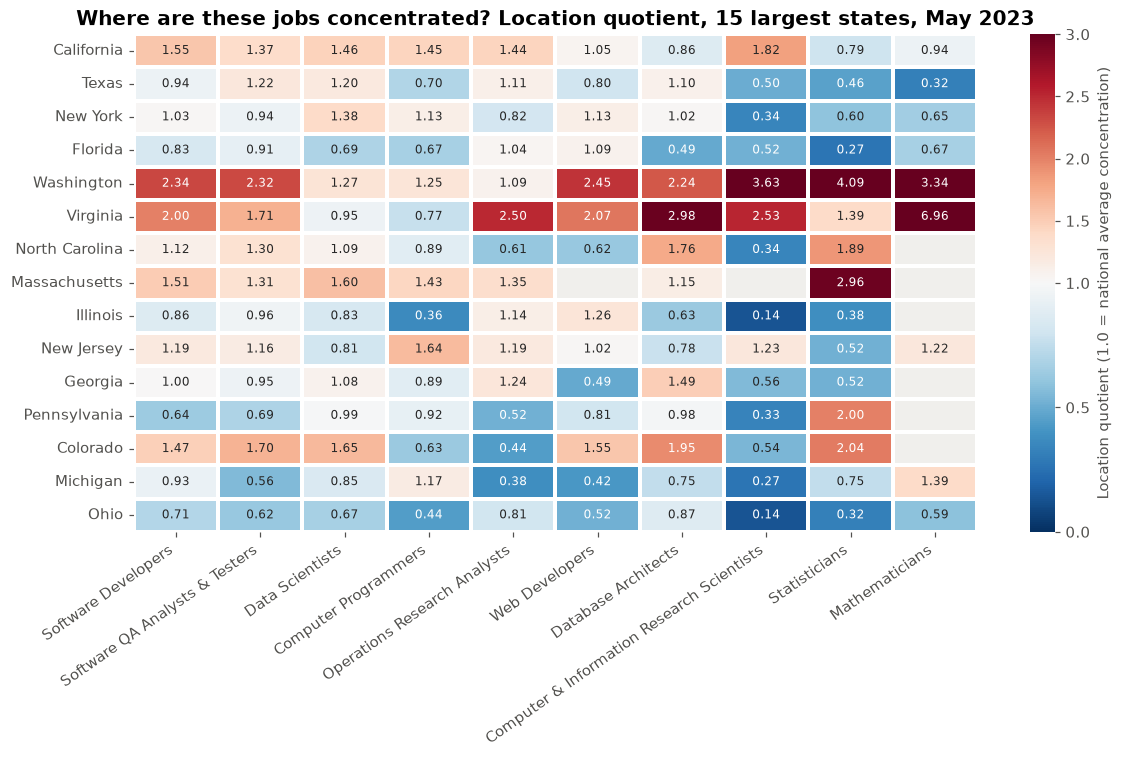

In [8]:
# state-level rows (AREA_TYPE 2) for our 10 jobs, with their short names and families attached
states = df[(df.AREA_TYPE == 2) & (df.OCC_CODE.isin(OCCUPATIONS))].merge(occ_map, left_on="OCC_CODE", right_index=True)
# the 15 states with the most workers in these jobs added together
top_states = states.groupby("AREA_TITLE").TOT_EMP.sum().nlargest(15).index
# column order for the grid: biggest job on the left
order = ai.sort_values("TOT_EMP", ascending=False).OCC

# reshape into a grid: one row per state, one column per job, each cell = location quotient
lq = (states[states.AREA_TITLE.isin(top_states)]
      .pivot_table(index="AREA_TITLE", columns="OCC", values="LOC_QUOTIENT")
      .reindex(index=top_states, columns=order))

fig, ax = plt.subplots(figsize=(11, 7))
# draw the heatmap: red = more concentrated than average, blue = less, white = average;
# TwoSlopeNorm makes 1.0 (the national average) the white middle of the scale;
# annot=True writes each number inside its cell (2 decimals)
sns.heatmap(lq, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=0, vcenter=1, vmax=3), annot=True, fmt=".2f",
            annot_kws=dict(fontsize=8), linewidths=1.5, linecolor="white",
            cbar_kws=dict(label="Location quotient (1.0 = national average concentration)"), ax=ax)
ax.set_facecolor("#f0efec"); ax.grid(False)   # missing cells (not published by the BLS) show as light grey
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("Where are these jobs concentrated? Location quotient, 15 largest states, May 2023")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()   # tilt the job names so they fit

### Here are my personal observations regarding the employment of AI:

Washington State is the number one tech hub. The concentration of software developers and computer and information research scientists is 2.3 times and 3.6 times higher in Washington than anywhere else across the US.
Virginia is number one in research and math roles (the concentration of computer and information research scientists is 2.5 times and mathematicians is 7 times higher).
California is better off than average across all job types, especially research scientists (1.8x) and data scientists (1.5x). Massachusetts ranks high in statistics (3.0 times) and data science (1.6x); hence, there is a close connection between the number of tech jobs and educational institutions.
Huge states like Texas, Florida, Ohio, and Illinois fall under the average level of AI research jobs.

## Visualization 6 - The 100% Stacked Bar Graph: Which Sectors of the Economy Utilize These Professions? 

Objective: Analysis and Comparison – Carrying out a comparison of the sectors employing three main professions: AI researchers, data scientists, and software engineers.
 
Why a 100% stacked bar graph: Here, we are interested in comparing proportions, rather than absolute values (which differ by a factor of 50!) – normalizing each bar leads to comparison being done based only on proportions of each sector in a given profession. Only five sectors are shown here, while the remaining sectors are grouped under "Other" in order for the graph not to be too colorful. National data from rows of the industry sector (I_GROUP = “industry”) are used for this visualization.

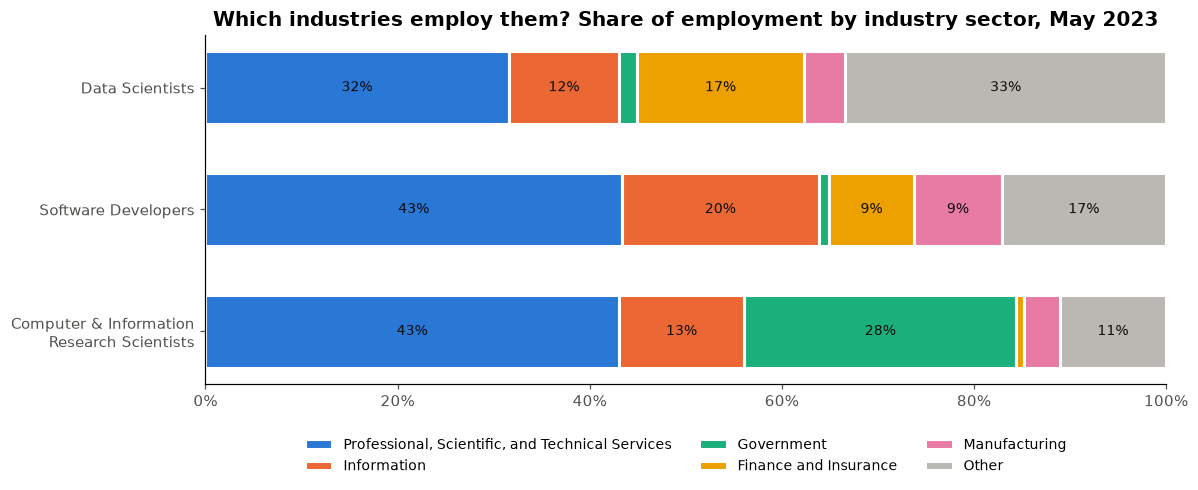

In [9]:
# the 3 jobs we compare (\n breaks a long name onto two lines)
focus = {"15-1221": "Computer & Information\nResearch Scientists", "15-2051": "Data Scientists", "15-1252": "Software Developers"}

# national rows split by industry sector, for those 3 jobs only
sectors = df[(df.AREA_TYPE == 1) & (df.I_GROUP == "sector") & (df.OCC_CODE.isin(focus))].copy()
sectors["SECTOR"] = sectors.NAICS_TITLE.str.replace(r" \(OEWS Designation\)", "", regex=True)  # remove extra text from names
sectors.loc[sectors.NAICS == "99", "SECTOR"] = "Government"   # sector 99 has a very long name, so shorten it

# grid: one row per job, one column per sector, each cell = number of workers (0 if none)
share = sectors.pivot_table(index="OCC_CODE", columns="SECTOR", values="TOT_EMP", aggfunc="sum").fillna(0)
share = share.div(share.sum(axis=1), axis=0)   # turn numbers into shares, so each row adds up to 100%
top = share.mean().nlargest(5).index           # the 5 sectors that matter most on average
# keep those 5, put everything else into "Other", and swap codes for readable names
share = share[top].assign(Other=1 - share[top].sum(axis=1)).rename(index=focus)

sector_colours = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", GREY]   # grey for "Other"
fig, ax = plt.subplots(figsize=(11, 4.6))

left = np.zeros(len(share))   # where each new piece starts: at 0 for the first sector
for col, c in zip(share.columns, sector_colours):
    # draw one sector's piece for all 3 bars, starting where the previous piece ended
    ax.barh(share.index, share[col], left=left, color=c, edgecolor="white", linewidth=2, label=col, height=0.6)
    # write the % in the middle of the piece, only if it's big enough (over 6%) to fit
    for i, v in enumerate(share[col]):
        if v > 0.06:
            ax.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="#0b0b0b")
    left += share[col].values   # move the starting point to the end of this piece

ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))   # axis shows 0%–100%
ax.set_xlim(0, 1); ax.grid(False)
ax.set_title("Which industries employ them? Share of employment by industry sector, May 2023")
ax.legend(ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.12), loc="upper center", fontsize=9)   # legend below the chart
plt.tight_layout(); plt.show()

### Here are my personal observations regarding the employment of AI:

Professional, Scientific, and Technical Services (consultancies, computer systems design, R&D firms) has been reported as the top employer of all three types of professions (32%-43%).
Government employs 28% of Computer and Information Research Scientists while not employing data scientists and software developers at all; many AI studies in the USA have been sponsored and conducted by public sectors agencies (defense, national laboratories).
The biggest number of data scientists work in Finance  and  Insurance area (17%) with 30% indulging in all other areas (health care, retail, manufacturing, education etc.); Data science appears in almost all sectors of the economy, not only in IT. Developers are mainly involved in Information sector (20%) working for publishing and internet companies.

## Visualization 7 – Lollipop chart: what cities have the number of AI Researchers?

Purpose: ranking – find out what metropolitan areas are leading in the field of Computer & Information Research Scientists.

Why use a lollipop chart: a lollipop chart is a way to compare a single quantitative attribute through the different categories (similar to bar chart), but has less ink due to the thin stem and dot. Ranking from the highest to the lowest value makes it easy to see the ranking at a glance and median wage is additionally shown as a text label to provide some additional information without requiring a second axis.

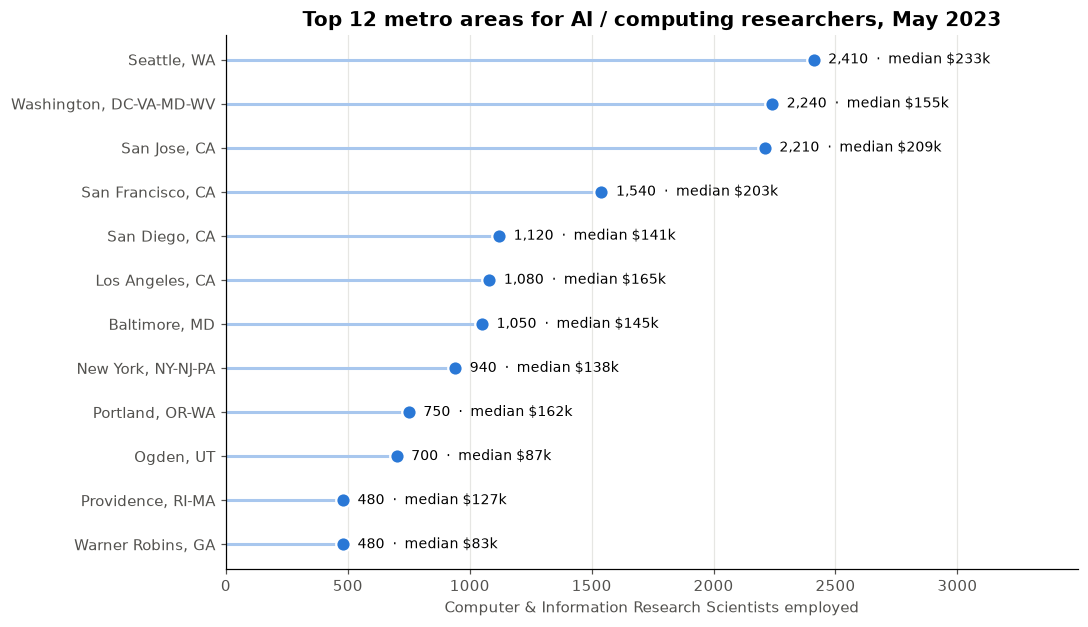

Top 12 metros hold 43% of all national CIRS jobs


In [10]:
# metro-area rows (AREA_TYPE 4) for AI researchers (code 15-1221); drop cities with no job count
metros = df[(df.AREA_TYPE == 4) & (df.OCC_CODE == "15-1221")].dropna(subset=["TOT_EMP"])
m = metros.nlargest(12, "TOT_EMP").sort_values("TOT_EMP")   # top 12 cities, smallest first (biggest ends up on top)
# shorten long names: "Seattle-Tacoma-Bellevue, WA" -> "Seattle, WA" (first city + state)
m["CITY"] = m.AREA_TITLE.str.split(",").str[0].str.split("-").str[0] + ", " + m.AREA_TITLE.str.split(", ").str[-1]

fig, ax = plt.subplots(figsize=(10, 5.8))
ax.hlines(m.CITY, 0, m.TOT_EMP, color="#a8c7ee", lw=2)   # the "stick": a thin line from 0 to the value
# the "candy": a dot at the end of each stick; zorder=3 puts it on top of the line
ax.scatter(m.TOT_EMP, m.CITY, s=90, color=FAMILY_COLOURS["AI & Computing Research"], zorder=3, edgecolor="white", linewidth=1.5)

# next to each dot: number of jobs and the median wage in thousands (n/a if the BLS didn't publish it)
for r in m.itertuples():
    wage = "n/a" if pd.isna(r.A_MEDIAN) else f"${r.A_MEDIAN / 1000:,.0f}k"
    ax.text(r.TOT_EMP + 60, r.CITY, f"{r.TOT_EMP:,.0f}  ·  median {wage}", va="center", fontsize=9)

ax.set_xlim(0, m.TOT_EMP.max() * 1.45)   # extra space on the right so the labels fit
ax.grid(axis="y", visible=False)
ax.set_xlabel("Computer & Information Research Scientists employed")
ax.set_title("Top 12 metro areas for AI / computing researchers, May 2023")
plt.tight_layout(); plt.show()

# what share of ALL US AI researchers work in these 12 cities
print(f"Top 12 metros hold {m.TOT_EMP.sum() / ai.set_index('OCC_CODE').loc['15-1221', 'TOT_EMP']:.0%} of all national CIRS jobs")

### Here are my personal observations regarding the employment of AI:

The cities known for their greatest amount of AI / computing scientists are Seattle (2,410), Washington D.C. (2,240), and San Jose / Silicon Valley (2,210).
Around 43% of the AI work positions in the U.S. are situated in the 12 largest metropolitan areas, which indicates that AI researches take place in relativity concentrated areas.
As for remuneration, one can observe that being employed in Seattle means earning 209k, while those working in Warner Robins (GA) and Ogden (UT) will have $87 000 to receive.

## 5. Challenge-upward trends of employment in AI (from May 2014 to May 2023):

The national OEWS files from May 2014 to May 2022 were downloaded from the same BLS tables page and merged with the May 2023 national rows analyzed above.

An important data issue is the switch in occupation codes. The SOC was revised in 2018; therefore, OEWS used a hybrid of the 2010 and 2018 codes during May of 2019 and 2020, and full 2018 SOC from May 2021 onward (BLS n.d.a). That meant that occupations had to be matched ("crosswalked") across years:

| Series | 2014–2018 (SOC 2010) | 2019–2020 (hybrid) | 2021–2023 (SOC 2018) |
|---|---|---|---|
| Computer & Information Research Scientists | 15-1111 | 15-1221 | 15-1221 |
| Data Scientists | *no code* | 15-2098 (data scientists + other math occupations) | 15-2051 |
| Software Developers & QA Testers | 15-1132 + 15-1133 (QA testers not included) | 15-1256 | 15-1252 + 15-1253 |
| Computer Programmers | 15-1131 | 15-1251 | 15-1251 |
| Statisticians / Operations Research Analysts | 15-2041 / 15-2031 | same | same |

In the 2018 Standard Occupational Classification, the term "Data Scientists" became an official job title (BLS, 2022), meaning that Data Scientists did not exist prior to 2019. Interruption periods due to code revisions have been highlighted in the graphs, as discussed below.

In [11]:
# a function that loads ONE year of national data, so we can call it for every year
def load_national(year):
    """Return national, all-industry rows for one year with harmonised (upper-case) columns."""
    if year == 2023:
        d = national.copy()   # 2023 is already loaded and cleaned, so just copy it
    else:
        # build the file name from the year, e.g. 2016 -> "oesm16nat.zip", and read it from the zip
        d = read_excel_from_zip(DATA_DIR / f"oesm{str(year)[2:]}nat.zip", r"national_M\d{4}_dl\.xlsx$")
        d.columns = d.columns.str.upper()   # some years use small letters in column names, so make them all CAPITALS
        for col in ["TOT_EMP", "A_MEAN", "A_MEDIAN"]:
            # replace '#' with that year's wage cap, then turn text into numbers ('*' becomes NaN)
            s = d[col].astype(str).str.strip().replace("#", "239200" if year >= 2022 else "208000")
            d[col] = pd.to_numeric(s, errors="coerce")
    d["YEAR"] = year   # add a column saying which year these rows are from
    return d[["YEAR", "OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEAN", "A_MEDIAN"]]   # keep only the columns we need

YEARS = range(2014, 2024)   # 2014 up to 2023 (the end number, 2024, is not included)
# load every year and stack them into one long table
hist = pd.concat([load_national(y) for y in YEARS], ignore_index=True)

# job codes changed in 2019–2021 (SOC 2010 -> SOC 2018), so this says
# which code(s) to use for each job in each year (the "crosswalk")
def codes_for(series, y):
    return {
        "Computer & Information Research Scientists": ["15-1111"] if y < 2019 else ["15-1221"],
        "Data Scientists": [] if y < 2019 else (["15-2098"] if y < 2021 else ["15-2051"]),   # no code before 2019
        "Software Developers & QA Testers": ["15-1132", "15-1133"] if y < 2019 else (["15-1256"] if y < 2021 else ["15-1252", "15-1253"]),
        "Computer Programmers": ["15-1131"] if y < 2019 else ["15-1251"],
        "Statisticians": ["15-2041"],                  # same code every year
        "Operations Research Analysts": ["15-2031"],   # same code every year
        "All occupations": ["00-0000"],                # whole USA, used for comparison
    }[series]

SERIES = ["Computer & Information Research Scientists", "Data Scientists", "Software Developers & QA Testers",
          "Computer Programmers", "Statisticians", "Operations Research Analysts", "All occupations"]

rows = []   # an empty list that we fill with one result per job per year
for y in YEARS:
    yd = hist[hist.YEAR == y]   # only this year's rows
    for s in SERIES:
        sub = yd[yd.OCC_CODE.isin(codes_for(s, y))]   # the row(s) for this job in this year
        if len(sub):   # skip if there's nothing (e.g. Data Scientists before 2019)
            emp = sub.TOT_EMP.sum()   # add up the jobs (some years combine 2 codes)
            # average wage weighted by jobs, so a bigger code counts more than a smaller one
            rows.append(dict(YEAR=y, SERIES=s, EMP=emp, A_MEAN=(sub.A_MEAN * sub.TOT_EMP).sum() / emp))

trend = pd.DataFrame(rows)   # turn the list into a table
# show it as a grid: years down the side, jobs across the top, number of jobs in each cell
trend.pivot(index="YEAR", columns="SERIES", values="EMP").astype("Int64")

SERIES,All occupations,Computer & Information Research Scientists,Computer Programmers,Data Scientists,Operations Research Analysts,Software Developers & QA Testers,Statisticians
YEAR,,,,,,,
2014,135128260,24210,302150,<NA>,86950,1068870,26970
2015,137896660,25510,289420,<NA>,95860,1138480,29870
2016,140400040,26580,271200,<NA>,109150,1203820,33440
2017,142549250,27920,247690,<NA>,106050,1243820,36540
2018,144733270,30070,230470,<NA>,104200,1308490,39920
2019,146875480,30780,199540,30810,99680,1406870,39090
2020,139099570,30220,178140,59680,96220,1476800,38860
2021,140886310,30840,152610,105980,98700,1554300,31370
2022,147886000,33780,132740,159630,105080,1731210,30780


## Visualisation 8 – Smaller multiple line graphs show employment trends throughout time

Aim: trend analysis - what changes have occurred to employment levels in the various professions over ten years?

Why smaller multiples of line graphs: for a quantitative variable over time, a line graph is the obvious solution, i.e. time (years) will be arranged in an increasing order. Moreover, the professions differ significantly concerning their populations (35,000 vs 1.9 million), so placing them on one graph would crush the smaller ones. Instead, the use of various panels (small multiples) shows the curves of various trends without losing the same proportions and colours.

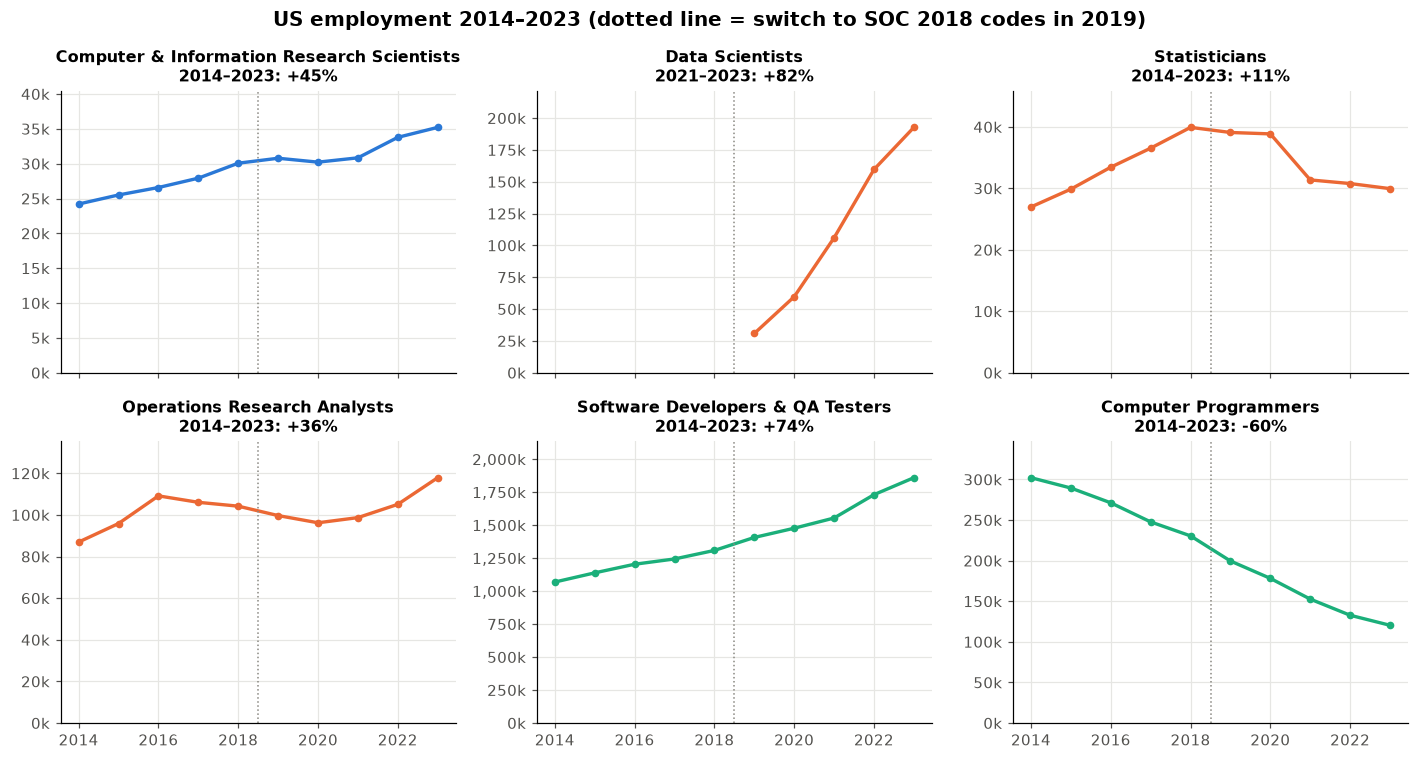

In [12]:
# each job gets the colour of its family (same colours as in the earlier charts)
SERIES_COLOURS = {
    "Computer & Information Research Scientists": FAMILY_COLOURS["AI & Computing Research"],
    "Data Scientists": FAMILY_COLOURS["Data Science & Analytics"],
    "Statisticians": FAMILY_COLOURS["Data Science & Analytics"],
    "Operations Research Analysts": FAMILY_COLOURS["Data Science & Analytics"],
    "Software Developers & QA Testers": FAMILY_COLOURS["Software Development"],
    "Computer Programmers": FAMILY_COLOURS["Software Development"],
}

# a grid of 6 small charts (2 rows x 3 columns) that all share the same years axis
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for ax, s in zip(axes.flat, SERIES_COLOURS):   # one small chart per job
    t = trend[trend.SERIES == s]   # this job's numbers for every year
    ax.plot(t.YEAR, t.EMP, color=SERIES_COLOURS[s], lw=2.2, marker="o", ms=4)   # line with a dot for each year
    ax.axvline(2018.5, color="#898781", ls=":", lw=1)   # dotted line where the job codes changed

    # % change from the first year to 2023, shown in the title
    # (Data Scientists start in 2021, because their final code only exists from then)
    t_base = t[t.YEAR >= 2021] if s == "Data Scientists" else t
    first, last = t_base.iloc[0], t_base.iloc[-1]
    ax.set_title(f"{s}\n{int(first.YEAR)}–2023: {last.EMP / first.EMP - 1:+.0%}", fontsize=10.5)

    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1000:,.0f}k"))   # 150000 -> "150k"
    ax.set_ylim(0, t.EMP.max() * 1.15)   # start at 0 so the changes aren't exaggerated, with a bit of space on top

fig.suptitle("US employment 2014–2023 (dotted line = switch to SOC 2018 codes in 2019)", fontweight="bold", fontsize=13)   # one title for the whole grid
plt.tight_layout(); plt.show()

### Here are my personal observations regarding the employment of AI overtime:

There was a considerable increase in the number of Data Scientists in just a span of two years, growing by +82% (105,980 in 2021 → 192,710 in 2023) which is surprising because this was the time when coding jobs were consistently gaining ground. The increase with respect to the number of Data Scientists since 2019 cannot solely be attributed to redesignation of jobs, as there has been real increase in jobs even after 2021.
Software developers and QA testers also saw a rise in numbers, growing from 1.07 million (2014) to 1.86 million (2023) (+74%), but one must consider the fact that QA testers were not included prior to 2019 meaning that the results are slightly inflated.
Computer and Information Research Scientists experienced an increase of +45%, which is especially seen after 2021.
However, Computer Programmers saw a decline of 60% (302k → 120k). Coding activities are becoming automated, and certain activities are now included in larger job roles called "software developers".
The highest number of Statisticians was seen in 2018, however, they experienced a decline in 2021 when the "Data Scientist" classification was created meaning that many job vacancies in the field of statistics were reassigned new names.

## Visualisation 9 – Indexed line chart: who has grown faster than the economy overall?

Purpose: to evaluate the growth dynamics over time.

Why the choice of indexed line chart. Indexed line chart is used to measure the growth of the different occupation sizes on a common axis. The entries use the convention that 2014 = 100 while expressing each series in indexed values. Indexed chart eliminates any chances for misunderstanding which might arise when using a dual-axis chart. Only occupations that possess comparable codes are taken into consideration.

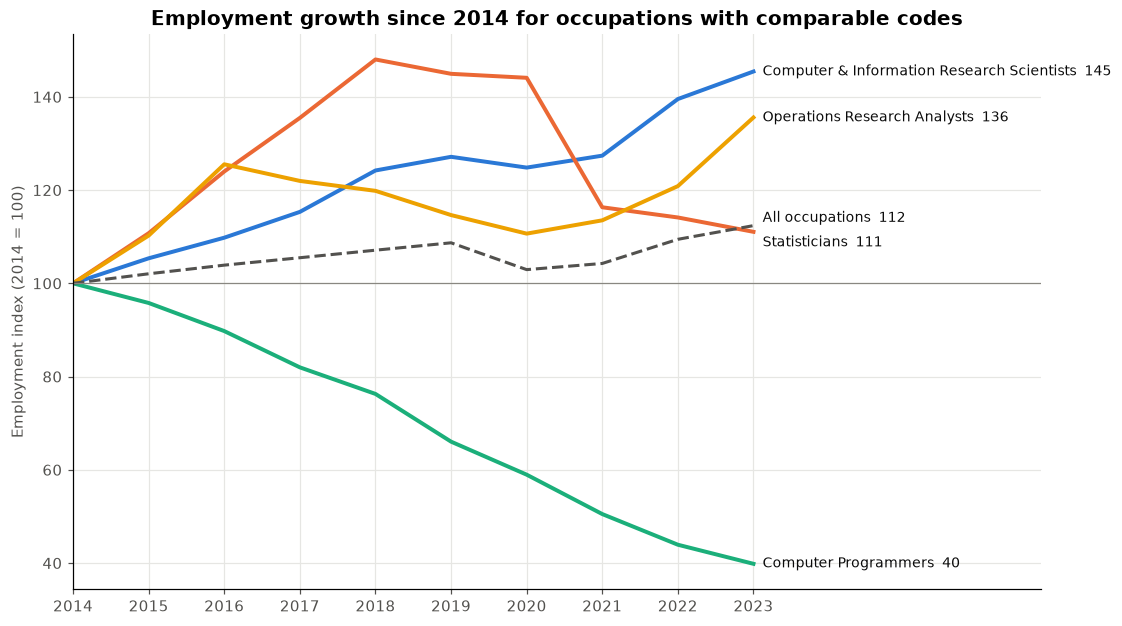

In [13]:
# only jobs whose codes are comparable across all years (no splits or merges), plus all jobs for comparison
consistent = ["Computer & Information Research Scientists", "Statisticians", "Operations Research Analysts",
              "Computer Programmers", "All occupations"]
# grid: years down the side, jobs across the top, number of jobs in each cell
idx = trend[trend.SERIES.isin(consistent)].pivot(index="YEAR", columns="SERIES", values="EMP")
# turn into an index: every job starts at 100 in 2014
# (e.g. 145 in 2023 = 45% more jobs than in 2014), so big and small jobs can share one axis
idx = idx / idx.loc[2014] * 100
line_colours = {"Computer & Information Research Scientists": "#2a78d6", "Statisticians": "#eb6834",
                "Operations Research Analysts": "#eda100", "Computer Programmers": "#1baf7a", "All occupations": "#52514e"}

fig, ax = plt.subplots(figsize=(10.5, 5.8))
for s in consistent:
    # one line per job; "All occupations" is dashed and thinner, because it's the benchmark
    ax.plot(idx.index, idx[s], lw=2.6 if s != "All occupations" else 2, color=line_colours[s],
            ls="--" if s == "All occupations" else "-")
    # write the job name and its 2023 value at the end of each line (instead of a legend);
    # nudge moves two labels up/down a little so they don't overlap
    nudge = {"Statisticians": -7, "All occupations": 5}.get(s, 0)
    ax.annotate(f"{s}  {idx[s].iloc[-1]:.0f}", (2023, idx[s].iloc[-1]), xytext=(6, nudge), textcoords="offset points",
                va="center", fontsize=9, color="#0b0b0b")

ax.axhline(100, color="#898781", lw=0.8)   # line at 100 = "same as 2014"; above it means growth, below means decline
ax.set_xlim(2014, 2026.8); ax.set_xticks(list(YEARS))   # extra space on the right for the labels, one tick per year
ax.set_ylabel("Employment index (2014 = 100)")
ax.set_title("Employment growth since 2014 for occupations with comparable codes")
plt.tight_layout(); plt.show()

### Here are my personal observations regarding the employment of AI overtime:

In the United States, the increase in jobs was 12 percent from 2014 to 2023 despite falling because of the COVID-19 pandemic in 2020, while job creation in occupations like Computer and Information Research Scientists (145) and Operations Research Analysts (136) took place at a much faster pace than general job growth – the former showed almost no impact from COVID-19. In contrast, Computer Programmers (40) experienced yearly drops. The labor market is expanding in areas related to Artificial Intelligence, but it is moving away from the traditional programming jobs and towards research and higher-level software development.

## Visualization 10 – Dumbbell chart: What has been the trend in salary levels? 

Purpose: to illuminate salary increments between two different points in time (before and after). 

Rationale for selecting the dumbbell chart: it depicts two pieces of information for each category (point in time in the past compared to 2023, and the gap between the two) and provides the change itself. It is easier to read than on the grouped bar chart for instance because it consumes less ink (the length of the "bar" or distance between the dots is the key factor for the size of the change) and the results and their growth percentages are placed next to the respective dumbbell. It is worth mentioning that the average salary of Software Developers and QA Testers is based on the weighted average of the two different positions.

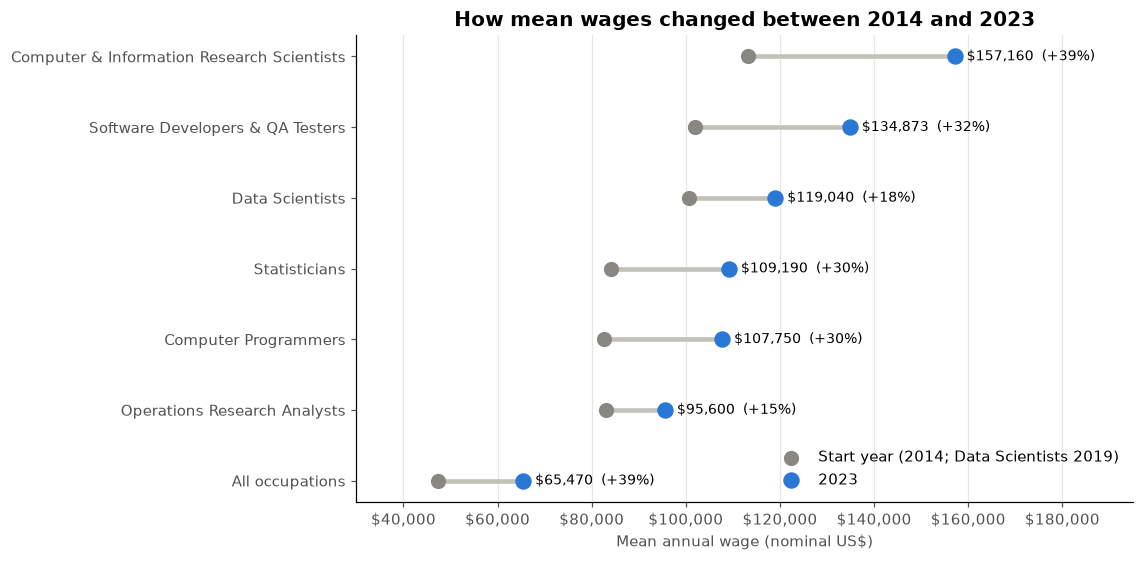

YEAR,start_year,start,2023,growth
SERIES,,,,
All occupations,2014,47230.000,65470.000,0.386
Operations Research Analysts,2014,82940.000,95600.000,0.153
Computer Programmers,2014,82690.000,107750.000,0.303
Statisticians,2014,84010.000,109190.000,0.300
Data Scientists,2019,100560.000,119040.000,0.184
Software Developers & QA Testers,2014,101862.602,134873.229,0.324
Computer & Information Research Scientists,2014,113190.000,157160.000,0.388


In [14]:
# mean wages for 3 years only: one row per job, one column per year
w = trend[trend.YEAR.isin([2014, 2019, 2023])].pivot(index="SERIES", columns="YEAR", values="A_MEAN")
# starting wage: use 2014, but if it's missing (Data Scientists) use 2019 instead
w["start"] = w[2014].fillna(w[2019]); w["start_year"] = np.where(w[2014].isna(), 2019, 2014)
w["growth"] = w[2023] / w.start - 1   # % change from the start year to 2023 (0.39 = +39%)
w = w.sort_values(2023)               # highest 2023 wage ends up at the top

fig, ax = plt.subplots(figsize=(10.5, 5.2))
ax.hlines(w.index, w.start, w[2023], color="#c3c2b7", lw=3)   # the "bar" of the dumbbell: from old wage to new wage
ax.scatter(w.start, w.index, s=80, color="#898781", zorder=3, label="Start year (2014; Data Scientists 2019)")   # grey dot = before
ax.scatter(w[2023], w.index, s=95, color="#2a78d6", zorder=3, label="2023")   # blue dot = 2023

# next to each blue dot: the 2023 wage and the % growth
for name, r in w.iterrows():
    ax.text(r[2023] + 2500, name, f"${r[2023]:,.0f}  ({r.growth:+.0%})", va="center", fontsize=9)

ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))   # axis shows $50,000 style
ax.set_xlim(30_000, 195_000)   # space on the right for the labels
ax.grid(axis="y", visible=False)
ax.set_xlabel("Mean annual wage (nominal US$)")   # nominal = NOT adjusted for inflation
ax.set_title("How mean wages changed between 2014 and 2023")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

# the same numbers as a table, rounded to 3 decimals
w[["start_year", "start", 2023, "growth"]].round(3)

### Here are my personal observations regarding the employment of AI overtime:

Computer & Information Research Scientists receive the highest salary, with average income growing by **39% to $157,160.** - Software Developers & QA Testers (+32%), Statisticians (+30%), and Programmers (+30%) also witness wage increases; however, **Operations Research Analysts (+15%) and Data Scientists (+18% since 2019) experienced lower increases**, which may be explained by increasing numbers of people working in this sector. - Interestingly, the overall mean wage also rose by 39% (partially due to the fact that many low-paid jobs have been eliminated during COVID-19 and low wages have increased afterwards). Thus, in percentage terms, AI-related salaries did **not grow faster than salaries across all occupations.** However, there is still a significant difference in dollar amounts ( +
44,000 for computer scientists vs +18,000 for all occupations) between salaries.

# References & Citations:

Hunter, J.D. (2007) 'Matplotlib: A 2D graphics environment', Computing in Science & Engineering, 9(3), pp. 90–95. doi: 10.1109/MCSE.2007.55.

Knaflic, C.N. (2015) Storytelling with Data: A Data Visualization Guide for Business Professionals. Hoboken, NJ: Wiley.

McKinney, W. (2010) 'Data structures for statistical computing in Python', in Proceedings of the 9th Python in Science Conference, pp. 56–61. doi: 10.25080/Majora-92bf1922-00a.

Office of Management and Budget (2018) Standard Occupational Classification Manual 2018. Washington, DC: Executive Office of the President. Available at: https://www.bls.gov/soc/2018/soc_2018_manual.pdf (Accessed: 2 November 2026).

U.S. Bureau of Labor Statistics (2015–2023) Occupational Employment and Wage Statistics: National data, May 2014 – May 2022 [Dataset]. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 2 November 2026).

U.S. Bureau of Labor Statistics (2022) 'Employment and wages for newly defined occupations, May 2021', The Economics Daily, 15 June. Available at: https://www.bls.gov/opub/ted/2022/employment-and-wages-for-newly-defined-occupations-may-2021.htm (Accessed: 2 November 2026).

U.S. Bureau of Labor Statistics (2024) Occupational Employment and Wage Statistics: All data, May 2023 [Dataset]. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 2 November 2026).

U.S. Bureau of Labor Statistics (n.d.a) Implementing the 2018 SOC in the OEWS program – May 2019 and May 2020 hybrid occupations. Available at: https://www.bls.gov/oes/soc_2018.htm (Accessed: 2 November 2026).

U.S. Bureau of Labor Statistics (n.d.b) Consumer Price Index (CPI). Available at: https://www.bls.gov/cpi/ (Accessed: 2 November 2026).

Waskom, M.L. (2021) 'seaborn: statistical data visualization', Journal of Open Source Software, 6(60), 3021. doi: 10.21105/joss.03021.